In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

import re
import nltk

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

print("NLTK resources downloaded!")

NLTK resources downloaded!


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


In [ ]:
df = pd.read_csv('/content/bitext_communication_intent_dataset.csv')

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (21534, 4)


In [ ]:
df.head()

,flags,utterance,category,intent
0,BILC,"I don't have an online account, what do I have...",ACCOUNT,create_account
1,BILQZ,can you tell me if i can regisger two accounts...,ACCOUNT,create_account
2,BPLC,"I have no online account, open one, please",ACCOUNT,create_account
3,BIPLD,"could you ask an agent how to open an account,...",ACCOUNT,create_account
4,BLQC,"i want an online account, create one",ACCOUNT,create_account


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21534 entries, 0 to 21533
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   flags      21534 non-null  object
 1   utterance  21534 non-null  object
 2   category   21534 non-null  object
 3   intent     21534 non-null  object
dtypes: object(4)
memory usage: 673.1+ KB


In [ ]:
df.columns

Index(['flags', 'utterance', 'category', 'intent'], dtype='object')

In [ ]:
print("Number of unique intents:", df['intent'].nunique())

print("\nIntent classes:")
print(df['intent'].unique())

Number of unique intents: 27

Intent classes:
['create_account' 'delete_account' 'edit_account' 'recover_password'
 'registration_problems' 'switch_account' 'check_cancellation_fee'
 'contact_customer_service' 'contact_human_agent' 'delivery_options'
 'delivery_period' 'complaint' 'review' 'check_invoices' 'get_invoice'
 'newsletter_subscription' 'cancel_order' 'change_order' 'place_order'
 'track_order' 'check_payment_methods' 'payment_issue'
 'check_refund_policy' 'get_refund' 'track_refund'
 'change_shipping_address' 'set_up_shipping_address']


In [ ]:
df['intent'].value_counts()

,count
intent,
payment_issue,4366
create_account,2122
contact_customer_service,2055
get_invoice,1430
track_order,1224
get_refund,1150
contact_human_agent,1026
check_invoices,1013
recover_password,986


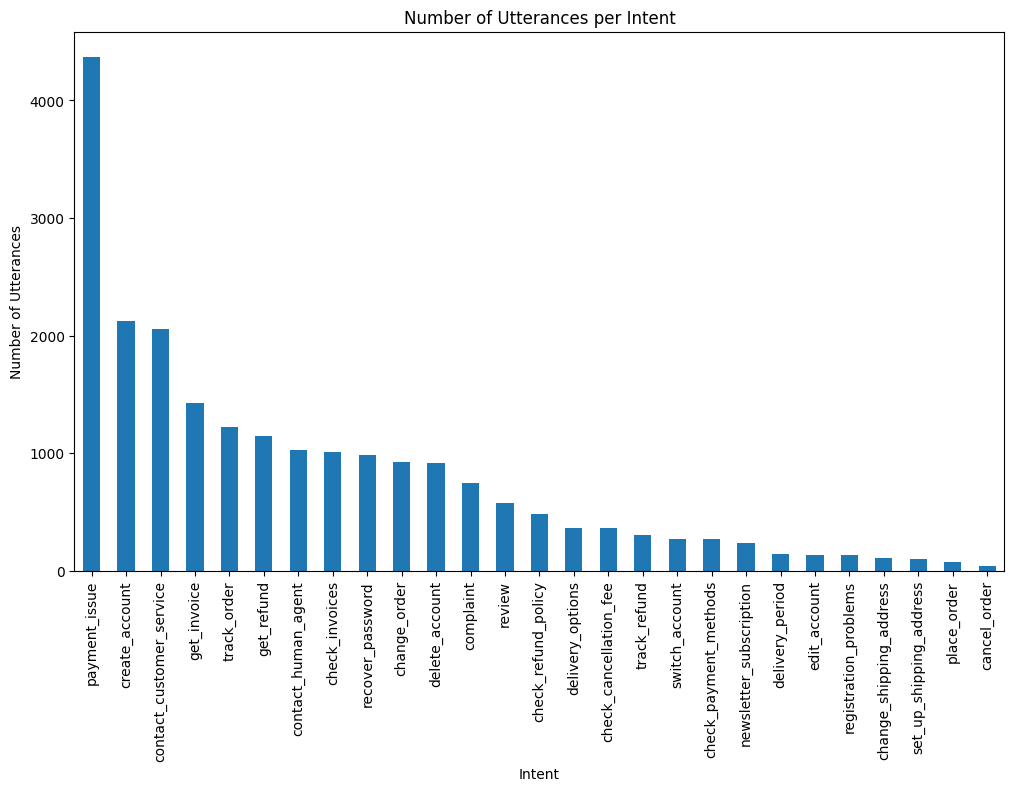

In [ ]:
plt.figure(figsize=(12, 7))

df['intent'].value_counts().plot(kind='bar')

plt.title('Number of Utterances per Intent')
plt.xlabel('Intent')
plt.ylabel('Number of Utterances')
plt.xticks(rotation=90)
plt.show()

In [ ]:
print(df.isnull().sum())

flags        0
utterance    0
category     0
intent       0
dtype: int64


In [ ]:
df = df.dropna(subset=['utterance', 'intent'])

print("Dataset shape after removing missing values:", df.shape)

Dataset shape after removing missing values: (21534, 4)


In [ ]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 12


In [ ]:
df = df.drop_duplicates()

print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (21522, 4)


In [ ]:
stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def preprocess_text(text):
    text = text.lower()

    # Remove special characters and numbers
    text = re.sub(r'[^a-zA-Z\s]', ' ', text)

    # Remove extra spaces
    text = re.sub(r'\s+', ' ', text).strip()

    # Tokenization
    words = text.split()

    # Remove stopwords and lemmatize
    words = [
        lemmatizer.lemmatize(word)
        for word in words
        if word not in stop_words
    ]

    return ' '.join(words)

In [ ]:
sample = "I want to track my order, please!"

print("Original:")
print(sample)

print("\nProcessed:")
print(preprocess_text(sample))

Original:
I want to track my order, please!

Processed:
want track order please


In [ ]:
df['clean_utterance'] = df['utterance'].apply(preprocess_text)

In [ ]:
df[['utterance', 'clean_utterance', 'intent']].head(10)

,utterance,clean_utterance,intent
0,"I don't have an online account, what do I have...",online account register,create_account
1,can you tell me if i can regisger two accounts...,tell regisger two account single email address,create_account
2,"I have no online account, open one, please",online account open one please,create_account
3,"could you ask an agent how to open an account,...",could ask agent open account please,create_account
4,"i want an online account, create one",want online account create one,create_account
5,"i want an account, i need help opening one",want account need help opening one,create_account
6,tell me if I can register two online accounts...,tell register two online account email,create_account
7,i want to know if i could create two profiles ...,want know could create two profile email address,create_account
8,can you tell me if i can create more than one ...,tell create one fucking user account email,create_account
9,were to create an onlind account,create onlind account,create_account


In [ ]:
X = df['clean_utterance']
y = df['intent']

In [ ]:
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (21522,)
y shape: (21522,)


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 17217
Testing samples: 4305


In [ ]:
tfidf = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2)
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)

Training TF-IDF shape: (17217, 6295)
Testing TF-IDF shape: (4305, 6295)


In [ ]:
model = LogisticRegression(
    max_iter=1000
)

model.fit(X_train_tfidf, y_train)

print("Model training completed!")

Model training completed!


In [ ]:
y_pred = model.predict(X_test_tfidf)

print("Predictions completed!")

Predictions completed!


In [ ]:
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)
print("Accuracy percentage:", round(accuracy * 100, 2), "%")

Accuracy: 0.9881533101045297
Accuracy percentage: 98.82 %


In [ ]:
print(classification_report(y_test, y_pred))

                          precision    recall  f1-score   support

            cancel_order       1.00      0.86      0.92         7
            change_order       0.99      0.99      0.99       185
 change_shipping_address       1.00      1.00      1.00        22
  check_cancellation_fee       1.00      1.00      1.00        72
          check_invoices       0.95      0.94      0.94       203
   check_payment_methods       1.00      0.93      0.96        54
     check_refund_policy       1.00      0.98      0.99        96
               complaint       1.00      0.99      1.00       149
contact_customer_service       1.00      1.00      1.00       411
     contact_human_agent       1.00      1.00      1.00       205
          create_account       0.99      1.00      0.99       424
          delete_account       0.99      0.98      0.99       183
        delivery_options       0.97      1.00      0.99        72
         delivery_period       1.00      1.00      1.00        28
         

In [ ]:
def predict_intent(text):
    cleaned_text = preprocess_text(text)

    text_tfidf = tfidf.transform([cleaned_text])

    prediction = model.predict(text_tfidf)[0]

    probabilities = model.predict_proba(text_tfidf)[0]
    confidence = np.max(probabilities)

    return prediction, confidence

In [ ]:
message = "I want to track my order"

intent, confidence = predict_intent(message)

print("Message:", message)
print("Predicted Intent:", intent)
print("Confidence:", round(confidence * 100, 2), "%")

Message: I want to track my order
Predicted Intent: track_order
Confidence: 95.63 %


In [ ]:
messages = [
    "I forgot my password",
    "I want my money back",
    "Where is my package?",
    "I want to cancel my order",
    "I need to contact customer support"
]

for message in messages:
    intent, confidence = predict_intent(message)

    print("\nMessage:", message)
    print("Intent:", intent)
    print("Confidence:", round(confidence * 100, 2), "%")


Message: I forgot my password
Intent: recover_password
Confidence: 94.31 %

Message: I want my money back
Intent: check_refund_policy
Confidence: 94.14 %

Message: Where is my package?
Intent: track_order
Confidence: 96.48 %

Message: I want to cancel my order
Intent: cancel_order
Confidence: 67.44 %

Message: I need to contact customer support
Intent: contact_customer_service
Confidence: 99.81 %


Importing Naive bayes

In [ ]:
from sklearn.naive_bayes import MultinomialNB

Training the Model

In [ ]:
nb_model = MultinomialNB()

nb_model.fit(X_train_tfidf, y_train)

print("Naive Bayes model trained successfully!")

Naive Bayes model trained successfully!


In [ ]:
nb_pred = nb_model.predict(X_test_tfidf)

In [ ]:
nb_accuracy = accuracy_score(y_test, nb_pred)

print("Naive Bayes Accuracy:", round(nb_accuracy * 100, 2), "%")

Naive Bayes Accuracy: 96.96 %


In [ ]:
print(classification_report(y_test, nb_pred))

                          precision    recall  f1-score   support

            cancel_order       0.00      0.00      0.00         7
            change_order       0.95      0.99      0.97       185
 change_shipping_address       1.00      0.86      0.93        22
  check_cancellation_fee       1.00      1.00      1.00        72
          check_invoices       0.98      0.88      0.92       203
   check_payment_methods       1.00      0.81      0.90        54
     check_refund_policy       1.00      0.97      0.98        96
               complaint       0.98      1.00      0.99       149
contact_customer_service       0.98      1.00      0.99       411
     contact_human_agent       1.00      1.00      1.00       205
          create_account       0.96      0.99      0.98       424
          delete_account       0.95      0.98      0.97       183
        delivery_options       0.99      0.99      0.99        72
         delivery_period       1.00      0.93      0.96        28
         

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


SVM Model

In [ ]:
from sklearn.svm import LinearSVC

In [ ]:
svm_model = LinearSVC()
svm_model.fit(X_train_tfidf, y_train)
print("SVM model trained successfully!")

SVM model trained successfully!


In [ ]:
svm_pred = svm_model.predict(X_test_tfidf)

In [ ]:
svm_accuracy = accuracy_score(y_test, svm_pred)
print("SVM Accuracy:", round(svm_accuracy * 100, 2), "%")

SVM Accuracy: 99.0 %


In [ ]:
print(classification_report(y_test, svm_pred))

                          precision    recall  f1-score   support

            cancel_order       1.00      0.86      0.92         7
            change_order       0.99      0.99      0.99       185
 change_shipping_address       1.00      1.00      1.00        22
  check_cancellation_fee       1.00      1.00      1.00        72
          check_invoices       0.95      0.95      0.95       203
   check_payment_methods       1.00      0.94      0.97        54
     check_refund_policy       1.00      1.00      1.00        96
               complaint       1.00      0.99      1.00       149
contact_customer_service       1.00      1.00      1.00       411
     contact_human_agent       1.00      1.00      1.00       205
          create_account       0.99      1.00      1.00       424
          delete_account       0.99      0.98      0.99       183
        delivery_options       0.97      0.99      0.98        72
         delivery_period       1.00      1.00      1.00        28
         

**Comparing **

model       → Logistic Regression

nb_model    → Naive Bayes

svm_model   → SVM

In [ ]:
results = pd.DataFrame({
    'Model': [
        'Logistic Regression',
        'Naive Bayes',
        'SVM'
    ],
    'Accuracy': [
        accuracy,
        nb_accuracy,
        svm_accuracy
    ]
})

results['Accuracy (%)'] = results['Accuracy'] * 100

results[['Model', 'Accuracy (%)']]

,Model,Accuracy (%)
0,Logistic Regression,98.815331
1,Naive Bayes,96.957027
2,SVM,99.001161


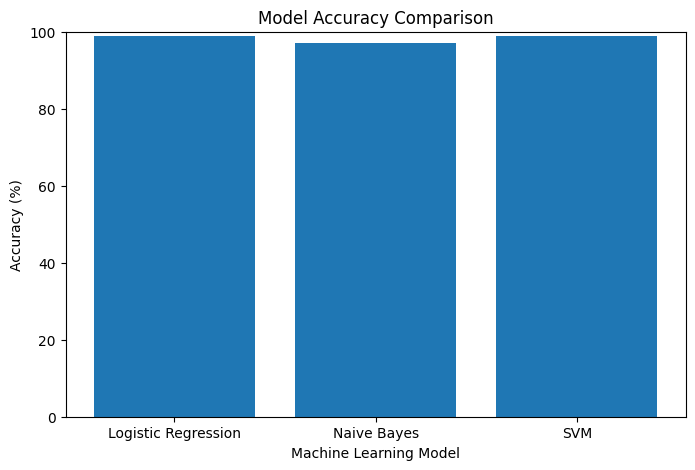

In [ ]:
plt.figure(figsize=(8, 5))

plt.bar(results['Model'], results['Accuracy (%)'])

plt.title('Model Accuracy Comparison')
plt.xlabel('Machine Learning Model')
plt.ylabel('Accuracy (%)')
plt.ylim(0, 100)

plt.show()

In [ ]:
best_model_name = results.loc[
    results['Accuracy'].idxmax(), 'Model'
]

best_accuracy = results['Accuracy'].max()

print("Best Model:", best_model_name)
print("Best Accuracy:", round(best_accuracy * 100, 2), "%")

Best Model: SVM
Best Accuracy: 99.0 %


In [ ]:
best_model = svm_model

In [ ]:
def predict_best_intent(text):
    cleaned_text = preprocess_text(text)

    text_tfidf = tfidf.transform([cleaned_text])

    prediction = best_model.predict(text_tfidf)[0]

    return prediction

In [ ]:
test_messages = [
    "I forgot my password",
    "Where is my order?",
    "I want to cancel my order",
    "I want a refund",
    "I need help with my payment"
]

for message in test_messages:
    prediction = predict_best_intent(message)

    print("Message:", message)
    print("Predicted Intent:", prediction)
    print("-" * 50)

Message: I forgot my password
Predicted Intent: recover_password
--------------------------------------------------
Message: Where is my order?
Predicted Intent: track_order
--------------------------------------------------
Message: I want to cancel my order
Predicted Intent: cancel_order
--------------------------------------------------
Message: I want a refund
Predicted Intent: get_refund
--------------------------------------------------
Message: I need help with my payment
Predicted Intent: payment_issue
--------------------------------------------------


In [ ]:
import joblib

In [ ]:
joblib.dump(best_model, 'intent_model.pkl')
joblib.dump(tfidf, 'tfidf_vectorizer.pkl')

print("Model and TF-IDF vectorizer saved successfully!")

Model and TF-IDF vectorizer saved successfully!
